# Evaluation of optimized version of LBM D2Q9

## Simulation parameters:
* Re    =
* omega =
* v_Nx  =
* L     =

In [7]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import re

from pathlib import Path

## Results visualization

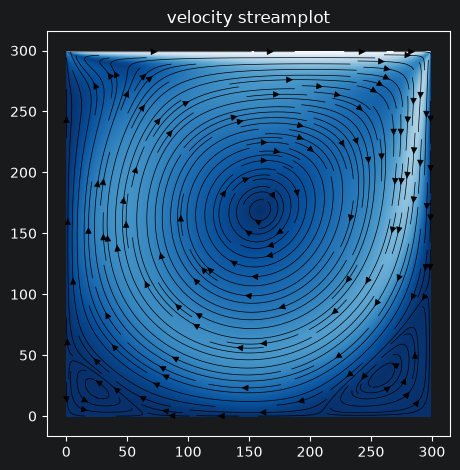

In [27]:
parent = '../out/optim_1'
file_base = "re1000-"
ext = ".tsv"

def _frame_generator(filename):
    """
    Zwraca kolejne DataFrame'y odpowiadające jednemu timestepowi.
    """

    reader = pd.read_csv(
        filename,
        sep = "\t",
        names = ["omega", "t", "y", "x", "rho", "uy", "ux"],
        chunksize = 4096,
    )

    buffer = pd.DataFrame()
    for chunk in reader:
        buffer = pd.concat([buffer, chunk], ignore_index=True)
        while len(buffer):
            t = buffer.iloc[0]["t"]
            mask = buffer["t"] == t
            # cały bufor należy do jednego timestepu
            if mask.all():
                break
            yield buffer[mask].copy()
            buffer = buffer[~mask].reset_index(drop=True)

    if len(buffer):
        yield buffer

def log_frame_reader(n):
    path = Path(parent) / str(n) / file_base
    stem = path.name

    pattern = re.compile( rf"{re.escape(stem)}(\d+){re.escape(ext)}$" )
    readers = []

    for file in sorted(path.parent.iterdir()):
        if not pattern.match(file.name):
            continue
        if file.stat().st_size == 0:
            continue
        readers.append(_frame_generator(file))

    if not readers:
        raise FileNotFoundError(f"No log files found for {stem}")

    while True:
        frames = []
        for reader in readers:
            try:
                frames.append(next(reader))
            except StopIteration:
                pass
        if not frames:
            break
        yield (
            pd.concat(frames, ignore_index=True)
              .sort_values(["y", "x"])
              .reset_index(drop=True)
        )


def field_streamplot(n, density=0.5):
    frames = log_frame_reader(n)
    frame = next(frames)

    square = frame['t'].values.size
    Nx = int(np.sqrt(square))

    x, y = np.meshgrid(np.arange(Nx), np.arange(Nx))
    ux = frame['ux'].values.reshape(Nx, Nx)
    uy = frame['uy'].values.reshape(Nx, Nx)
    speed = np.sqrt(ux**2 + uy**2)

    plt.imshow(speed, cmap="Blues_r")
    plt.streamplot(
            x, y, ux, uy,
            density = density,
            linewidth= 0.5,
            color = 'black'
    )
    plt.gca().invert_yaxis()

    plt.title(f"velocity streamplot")
    plt.tight_layout()
    plt.show()


field_streamplot(4, density=2.0)

## scaling statistics

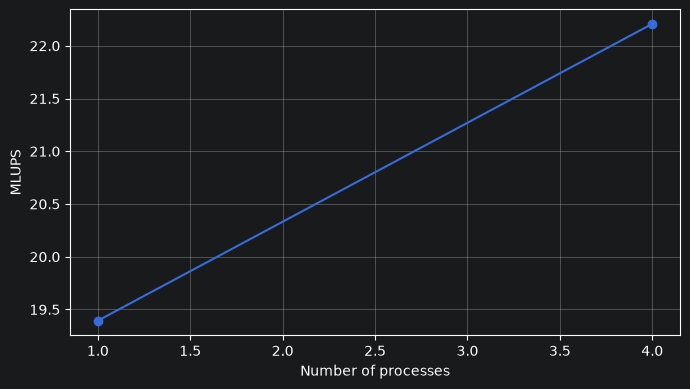

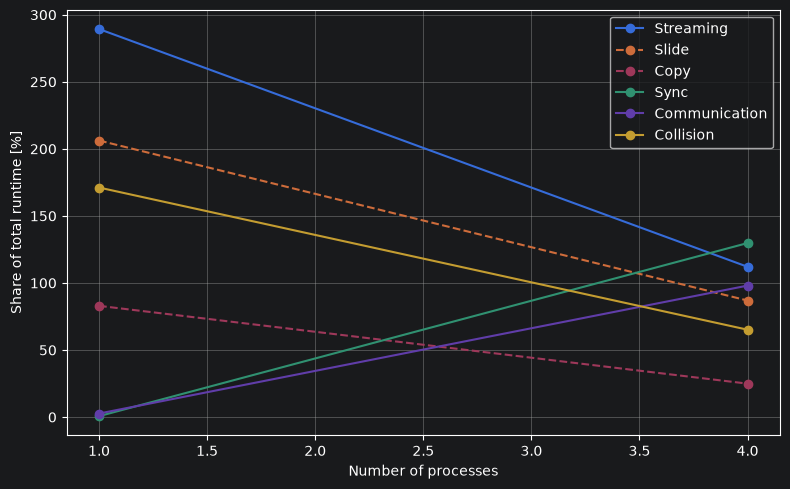

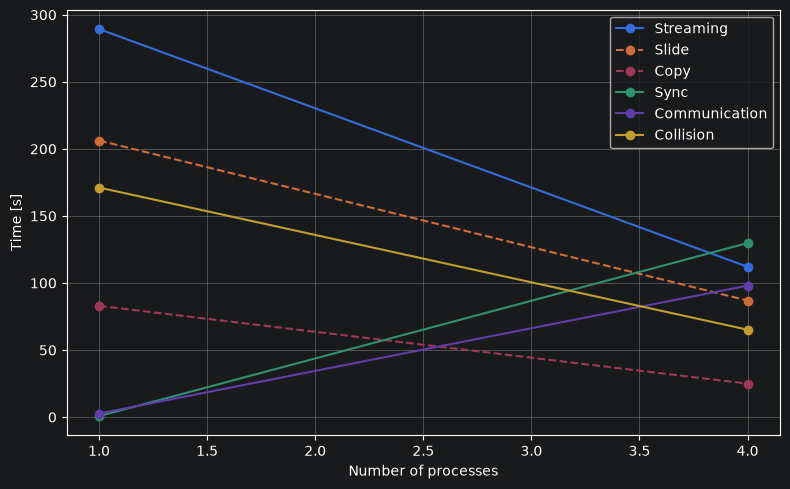

In [37]:
df = pd.read_csv(
        f"../out/optim_1/stats.tsv",
        sep = "\t",
        names = ["n", "i", "MLUPS", "total", "streaming", "sliding", "copy", "sync", "communication", "collision"]
)

# df = df[["n", "i", "MLUPS", "total", "streaming", "communication", "collision"]]

# średnia po wszystkich obrazach
avg = (
    df.groupby("n", as_index = False)
      .agg({
          "MLUPS"	        : "mean",
          "total"	        : "mean",
          "streaming"       : "mean",
          "sliding"		    : "mean",
          "copy"		    : "mean",
          "sync"            : "mean",
          "communication"	: "mean",
          "collision"		: "mean",
      })
)

# MLUPS
plt.figure(figsize = (7, 4))
plt.plot(avg["n"], avg["MLUPS"], "o-")
plt.xlabel("Number of processes")
plt.ylabel("MLUPS")
plt.grid(True)
plt.tight_layout()
plt.show()


# Relative execution time
relative = avg.copy()

for col in ["streaming", "sliding", "copy", "sync", "communication", "collision"]:
    relative[col] = 100.0 * relative[col] / relative["total"]

plt.figure(figsize = (8, 5))

for col, label, style in [
    ("streaming", "Streaming", 'o-'),
    ("sliding", "Slide", 'o--'),
    ("copy", "Copy", 'o--'),
    ("sync", "Sync", 'o-'),
    ("communication", "Communication", 'o-'),
    ("collision", "Collision", 'o-'),
]:
    plt.plot(avg["n"], avg[col], style, label = label)

plt.xlabel("Number of processes")
plt.ylabel("Share of total runtime [%]")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# Absolute times
plt.figure(figsize = (8, 5))

for col, label, style in [
    ("streaming", "Streaming", 'o-'),
    ("sliding", "Slide", 'o--'),
    ("copy", "Copy", 'o--'),
    ("sync", "Sync", 'o-'),
    ("communication", "Communication", 'o-'),
    ("collision", "Collision", 'o-'),
]:
    plt.plot(avg["n"], avg[col], style, label=label)

plt.xlabel("Number of processes")
plt.ylabel("Time [s]")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()